In [1]:
from fractal_printer.mesh import fractal_sdfs as fs, mesh_generation as mg
import numpy as np
from importlib import reload
import quaternion
import sdf
import matplotlib.pyplot as plt
from fractal_printer.paths import OUTPUT_DIR
from importlib import reload

In [ ]:


# Storm, to look for issues
reload(fs)
reload(mg)
settings = {
    "coefficients": [
        [-1.0, -1.0, 0.33099999999999996, 0.0],
        [0.0, -0.041999999999999926, -0.0030000000000000027, 0.15799999999999992],
        [0.5800000000000001, 0.0, 0.0, 0.0],
        [0, 0, 0, 0],
        [0, 0, 0, 0],
        [0, 0, 0, 0],
        [0, 0, 0, 0],
        [0, 0, 0, 0],
        [0, 0, 0, 0]
    ],
    "power": 2,
    "bailout": 1e50,
    "slice": 0.0,
    "offset": 0.01,
    "iterations": 20
}

for bailout in [1e10,1e20,1e30,1e40,1e50,1e60]:
    settings["bailout"] = bailout
    julia = fs.polynomial_julia_sdf(**settings)
    mesh = mg.generate_mesh(
        sdf = julia,
        samples = 2**25,
        recursion_levels = 0,
        bounds = mg.box_bounds(size=2),
        save_path=OUTPUT_DIR / f"storm_debug_{bailout:.1g}_bailout.ply"
    )

min -1, -1, -1
max 1, 1, 1
step 0.00620079, 0.00620079, 0.00620079
36926037 samples in 1331 batches with 1 workers
  100% (1331 of 1331) [##############################] 0:00:03 0:00:00    
726 skipped, 605 nonempty
8 cell-interior vertices held in the side table
1604776 triangles in 3.34085 seconds
Bisecting 806945 unique edge crossings (deduped from 858542, up to 0 levels, tol=1e-08)...
Converting mesh...
Saving mesh to C:\Users\owenb\Code\personal\fractal-printer\outputs\storm_debug_1e+10_bailout.ply...
min -1, -1, -1
max 1, 1, 1
step 0.00620079, 0.00620079, 0.00620079
36926037 samples in 1331 batches with 1 workers
  100% (1331 of 1331) [##############################] 0:00:03 0:00:00    
725 skipped, 606 nonempty
10 cell-interior vertices held in the side table
1600162 triangles in 3.44 seconds
Bisecting 804626 unique edge crossings (deduped from 856132, up to 0 levels, tol=1e-08)...
Converting mesh...
Saving mesh to C:\Users\owenb\Code\personal\fractal-printer\outputs\storm_debug

In [3]:
# Test case 
reload(fs)
settings = {
    "coefficients": [
        [-1.0, -1.0, 0.33099999999999996, 0.0],
        [0.0, -0.041999999999999926, -0.0030000000000000027, 0.15799999999999992],
        [0.5800000000000001, 0.0, 0.0, 0.0],
        [0, 0, 0, 0],
        [0, 0, 0, 0],
        [0, 0, 0, 0],
        [0, 0, 0, 0],
        [0, 0, 0, 0],
        [0, 0, 0, 0]
    ],
    "power": 2,
    "bailout": 10000,
    "slice": 0.0,
    "offset": 0.01,
    "iterations": 20
}

julia = fs.polynomial_julia_sdf(**settings)

# Test points
bad = [
    (0.110032, 0.225251, -0.180295),
    (0.16062, 0.0209423, 0.215949),
    (-0.00308803, 0.0206739, 0.145589)
]
good = [
    (0.172732, 0.27095, -0.121969),
    (0.240502, 0.24666, -0.201784),
    (-0.192578, -1, 0.457185)
]

for i,point in enumerate(bad + good):
    print(i)
    distance = julia(np.array([point]))
    print(distance)


0
[[-0.00025255]]
1
[[0.00245732]]
2
[[-0.00383059]]
3
[[-1.30422461e-06]]
4
[[9.19701706e-06]]
5
[[-0.00039022]]


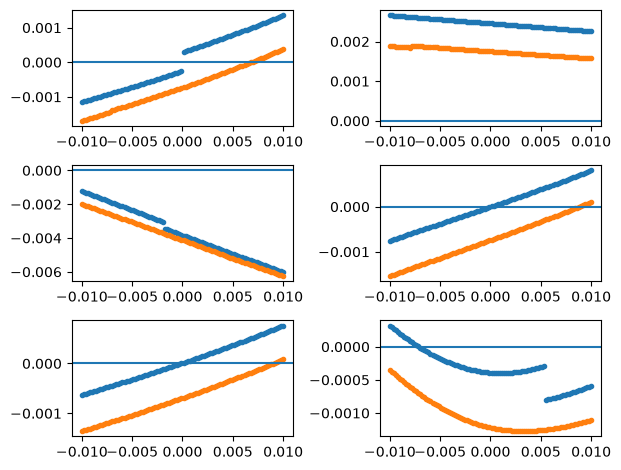

In [26]:
# look at the distance estimator along a line
reload(fs)
settings = {
    "coefficients": [
        [-1.0, -1.0, 0.33099999999999996, 0.0],
        [0.0, -0.041999999999999926, -0.0030000000000000027, 0.15799999999999992],
        [0.5800000000000001, 0.0, 0.0, 0.0]
    ],
    "power": 2,
    "bailout": 10000,
    "slice": 0.0,
    "offset": 0.01,
    "iterations": 40
}

julia_base = fs.polynomial_julia_sdf(**settings)
settings["bailout"] = 1e50
julia_mod = fs.polynomial_julia_sdf(**settings)

import matplotlib.pyplot as plt
fig, axes = plt.subplots(3,2)
axes = axes.flatten()
offsets = np.linspace(-0.01,0.01,100)
for case, ax in zip(bad + good, axes):
    point = np.array(case)
    vec = point / np.sqrt(np.sum(point**2))
    path = point[np.newaxis,:] + vec[np.newaxis,:] * offsets[:,np.newaxis]
    values_base = julia_base(path)
    values_mod = julia_mod(path)
    ax.plot(offsets, values_base,".")
    ax.plot(offsets, values_mod, ".")
    ax.axhline(0)

fig.tight_layout()

In [5]:
# Look for problem vertecies

mesh.cells

[<meshio CellBlock, type: triangle, num cells: 1625884, tags: []>]